# 01. Подготовка и диагностика данных


In [1]:
knitr::opts_chunk$set(
  echo = FALSE,
  message = FALSE,
  warning = FALSE,
  fig.align = "center",
  fig.width = 9,
  fig.height = 5
)


# О документе

Отчёт проверяет качество сырых измерений **производительности** перед тем, как строить прогнозные оценки.

| | |
|---|---|
| **Данные** | `data/metric_output.csv` |
| **Цель** | Найти выбросы, проверить нормальность, гомоскедастичность, мультиколлинеарность и автокорреляцию |
| **Результат** | Решение, можно ли подавать массив в модель как есть или нужна другая спецификация дисперсии |


In [2]:
library(dplyr)
library(nortest)
library(e1071)
library(car)
library(MASS)
library(FSA)
library(nlme)
library(lmtest)
library(sandwich)
library(fixest)
library(ggplot2)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Loading required package: carData



Attaching package: ‘car’



The following object is masked from ‘package:dplyr’:

    recode



... (9 outputs left out)


Attaching package: ‘zoo’



The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric




Attaching package: ‘fixest’



The following object is masked from ‘package:FSA’:

    se



In [3]:
dataset <- read.csv("data/metric_output.csv")
cat_columns <- c("quarter", "factory")
num_columns <- c("age", "batch_size", "mass", "temp", "pressure", "humidity")
cat_formula <- reformulate(cat_columns, response = "target")
num_formula <- reformulate(num_columns, response = "target")
trait <- "target"


# 1. Характеристика массива

Краткая сводка по всем полям выборки.


In [4]:
summary(dataset)


    item_id         target            quarter        factory         
 Min.   :   1   Min.   :   5.168   Min.   :1.000   Length:6000       
 1st Qu.: 786   1st Qu.:  23.895   1st Qu.:1.000   Class :character  
 Median :1532   Median :  33.507   Median :2.000   Mode  :character  
 Mean   :1526   Mean   :  45.736   Mean   :2.494                     
 3rd Qu.:2253   3rd Qu.:  49.203   3rd Qu.:3.000                     
 Max.   :3000   Max.   :1650.827   Max.   :4.000                     
      year         batch_no         age          batch_size      mass       
 Min.   :2012   Min.   :1.00   Min.   : 1.00   Min.   : 1   Min.   :0.9076  
 1st Qu.:2018   1st Qu.:2.00   1st Qu.:14.00   1st Qu.: 9   1st Qu.:3.6010  
 Median :2021   Median :3.00   Median :18.00   Median :12   Median :4.2070  
 Mean   :2020   Mean   :2.98   Mean   :18.04   Mean   :12   Mean   :4.2012  
 3rd Qu.:2023   3rd Qu.:4.00   3rd Qu.:22.00   3rd Qu.:15   3rd Qu.:4.8042  
 Max.   :2024   Max.   :5.00   Max.   :38.00   M

Распределение целевого показателя по заводам:


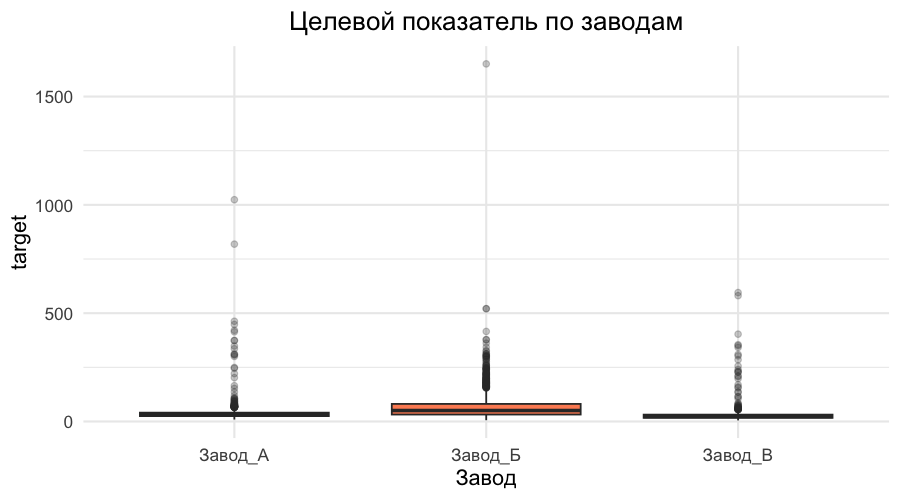

In [5]:
ggplot(dataset, aes(x = factory, y = target, fill = factory)) +
  geom_boxplot(outlier.alpha = 0.25) +
  scale_fill_brewer(palette = "Set2", guide = "none") +
  labs(title = "Целевой показатель по заводам", x = "Завод", y = "target") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


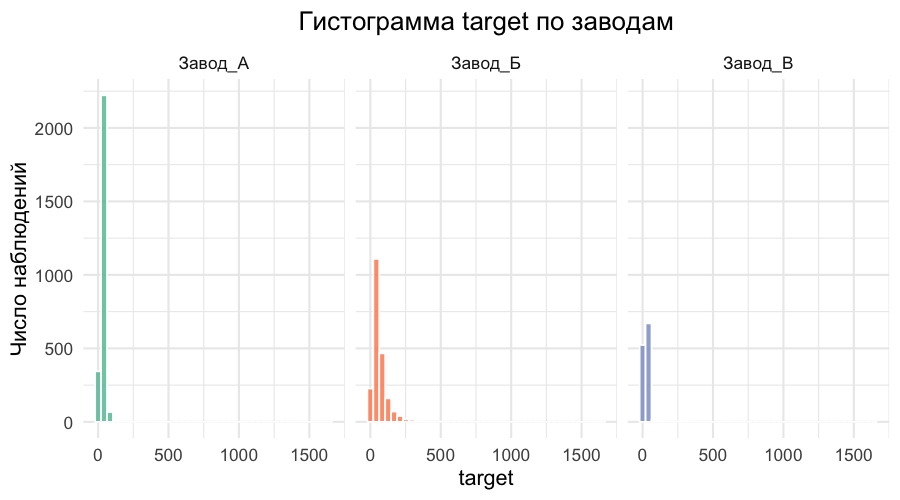

In [6]:
ggplot(dataset, aes(x = target, fill = factory)) +
  geom_histogram(bins = 40, color = "white", alpha = 0.85) +
  facet_wrap(~factory, ncol = 3) +
  scale_fill_brewer(palette = "Set2", guide = "none") +
  labs(title = "Гистограмма target по заводам", x = "target", y = "Число наблюдений") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# 2. Выбросы и аномалии


In [7]:
z_score_test <- function(array, threshold) {
  array <- na.omit(array)
  mean_array <- mean(array)
  sd_array <- sd(array)
  z_scores <- abs((array - mean_array) / sd_array)
  outliers <- array[z_scores > threshold]
  return(outliers)
}

plot_distribution <- function(array, name) {
  plot(
    array,
    type = "p",
    pch = 19,
    col = "steelblue",
    main = paste("1D-распределение переменной", name),
    xlab = "Индекс",
    ylab = "Переменная"
  )
}

qqplot_distribution <- function(array, name) {
  qqnorm(
    array,
    main = paste("QQ-plot распределения переменной", name),
    xlab = "Теоретические квантили",
    ylab = "Квантили массива"
  )
  qqline(array, col = "firebrick")
}


Распределение целевого показателя:


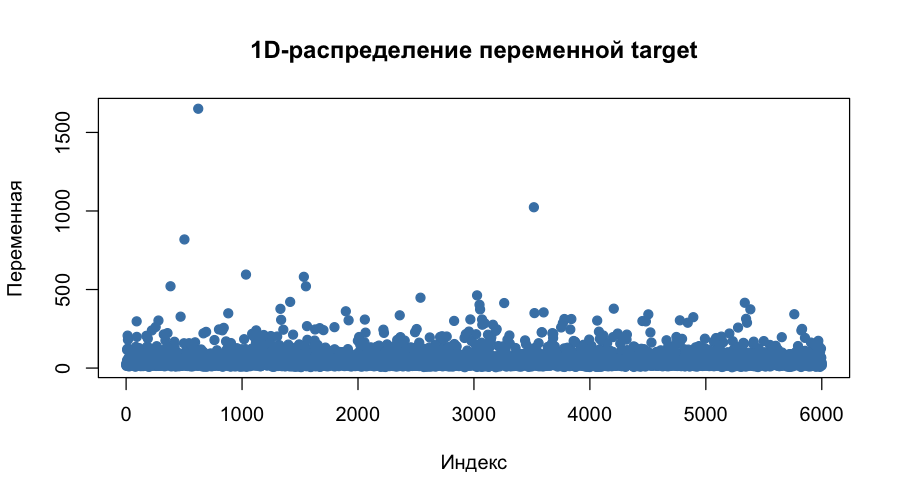

In [8]:
plot_distribution(dataset$target, "target")


Проверка целевого показателя на выбросы по z-оценке:


In [9]:
trait_outliers <- z_score_test(dataset$target, 0.2)


Получено значительное число выбросов — их исключаем.


In [10]:
corr_dataset <- dataset %>%
  mutate(across(all_of(cat_columns), as.factor)) %>%
  filter(!(target %in% trait_outliers))


Распределение после очистки:


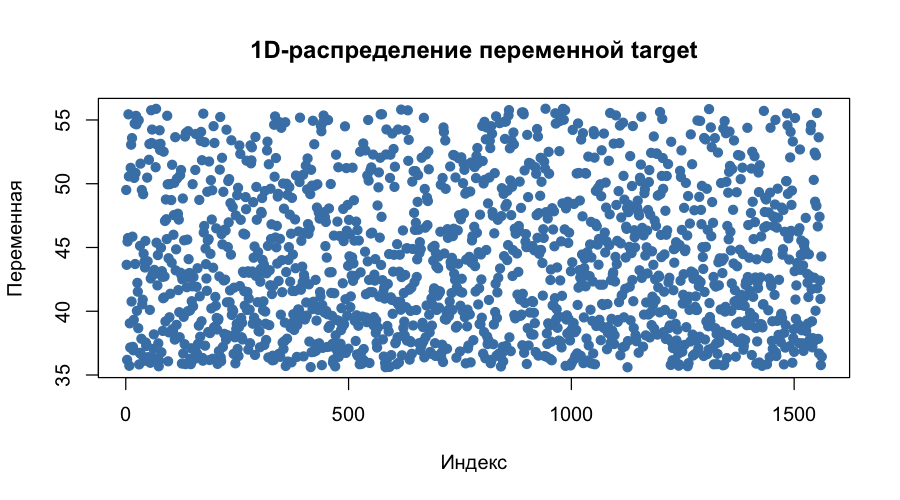

In [11]:
plot_distribution(corr_dataset$target, "target")


# 3. Нормальность

Классический тест Шапиро–Уилка здесь не подходит: в массиве больше 5000 строк. Используем тест Андерсона–Дарлинга.


In [12]:
ad.test(corr_dataset$target)



	Anderson-Darling normality test

data:  corr_dataset$target
A = 24.895, p-value < 2.2e-16



QQ-plot:


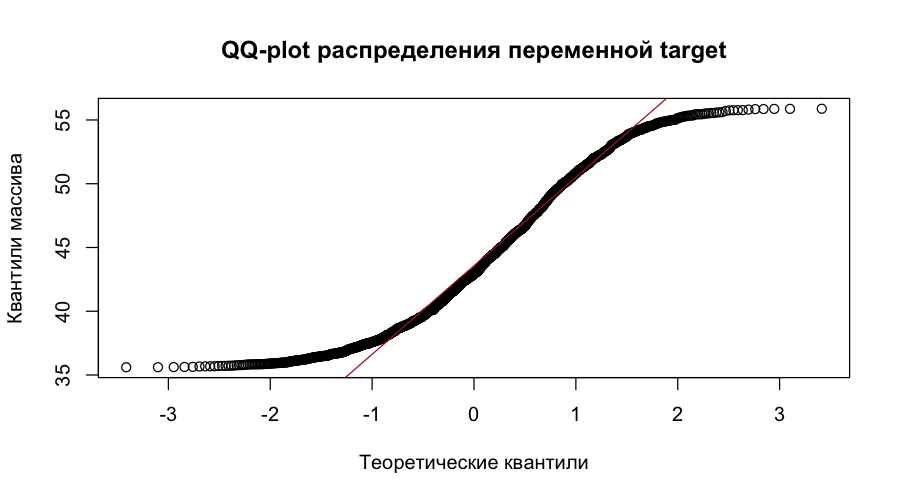

In [13]:
qqplot_distribution(corr_dataset$target, "target")


Асимметрия:


In [14]:
skewness(corr_dataset$target)


[1] 0.409877


Если skewness > 0, у распределения длинный правый хвост.

Эксцесс:


In [15]:
kurtosis(corr_dataset$target)


[1] -0.9832063


Если kurtosis > 0, хвосты тяжёлые, распределение лептокуртическое.

# 4. Гомоскедастичность


In [16]:
model <- lm(target ~ quarter * year * factory, data = corr_dataset)
coeftest(model, vcov. = vcovHC(model, type = "HC1"))



t test of coefficients:

                                Estimate  Std. Error t value Pr(>|t|)  
(Intercept)                  -469.272068  215.116812 -2.1815  0.02930 *
quarter2                       20.274683  332.326735  0.0610  0.95136  
quarter3                       87.524413  357.673001  0.2447  0.80672  
quarter4                      508.077454  337.615751  1.5049  0.13256  
year                            0.253292    0.106472  2.3790  0.01748 *
factoryЗавод_Б                146.024136  376.647167  0.3877  0.69830  
factoryЗавод_В                651.687322  693.742291  0.9394  0.34768  
quarter2:year                  -0.010022    0.164470 -0.0609  0.95142  
quarter3:year                  -0.042608    0.177005 -0.2407  0.80981  
quarter4:year                  -0.250964    0.167110 -1.5018  0.13336  
quarter2:factoryЗавод_Б       297.071048  557.020192  0.5333  0.59389  
quarter3:factoryЗавод_Б       307.515518  571.433017  0.5381  0.59055  
quarter4:factoryЗавод_Б      -745.6834

In [17]:
corr_corr_dataset <- corr_dataset %>%
  filter(
    (factory == "Завод_А" & quarter == 4) |
      (factory == "Завод_А" & quarter == 2) |
      (factory == "Завод_Б" & quarter == 3)
  )


In [18]:
levene_formula <- paste("target ~", paste(cat_columns, collapse = "*"))
leveneTest(as.formula(levene_formula), data = corr_corr_dataset)


Levene's Test for Homogeneity of Variance (center = median)
       Df F value Pr(>F)  
group   2  4.1914 0.0156 *
      563                 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


Если гомоскедастичность нарушена, данные гетероскедастичны. Смотрим остатки простой линейной модели на QQ-plot.


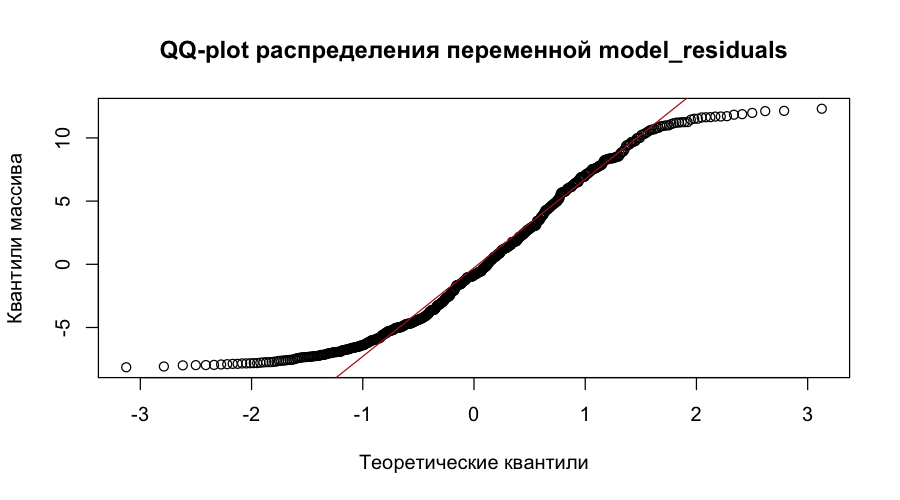

In [19]:
cat_model <- lm(target ~ year, data = corr_corr_dataset)
qqplot_distribution(resid(cat_model), "model_residuals")


In [20]:
weights <- 1 / exp(corr_dataset$target)^2
wls_model <- lm(
  target ~ quarter * year * factory,
  data = corr_dataset,
  weights = weights
)
summary(wls_model)


essentially perfect fit: summary may be unreliable



Call:
lm(formula = target ~ quarter * year * factory, data = corr_dataset, 
    weights = weights)

Weighted Residuals:
       Min         1Q     Median         3Q        Max 
-1.805e-16  4.000e-21  7.060e-19  2.119e-17  1.102e-16 

Coefficients:
                               Estimate Std. Error t value Pr(>|t|)    
(Intercept)                   3.757e+01  1.551e+01   2.423  0.01550 *  
quarter2                     -1.023e+02  3.148e+01  -3.250  0.00118 ** 
quarter3                     -2.546e+01  2.582e+01  -0.986  0.32421    
quarter4                      6.170e+01  2.133e+01   2.893  0.00387 ** 
year                         -6.928e-04  7.676e-03  -0.090  0.92810    
factoryЗавод_Б                2.346e+02  4.417e+01   5.311 1.25e-07 ***
factoryЗавод_В               -3.403e+02  1.047e+02  -3.251  0.00118 ** 
quarter2:year                 5.065e-02  1.558e-02   3.251  0.00118 ** 
quarter3:year                 1.254e-02  1.278e-02   0.981  0.32660    
quarter4:year                -3.

In [21]:
gls_model <- gls(
  target ~ factory,
  data = corr_dataset,
  weights = varIdent(form = ~ 1 | factory)
)
summary(gls_model)


Generalized least squares fit by REML
  Model: target ~ factory 
  Data: corr_dataset 
       AIC      BIC    logLik
  9846.267 9878.378 -4917.134

Variance function:
 Structure: Different standard deviations per stratum
 Formula: ~1 | factory 
 Parameter estimates:
  Завод_А   Завод_Б   Завод_В 
1.0000000 1.0698953 0.9352867 

Coefficients:
                  Value Std.Error   t-value p-value
(Intercept)    43.14474 0.1903286 226.68547   0.000
factoryЗавод_Б  2.01979 0.3178968   6.35360   0.000
factoryЗавод_В  0.09526 0.4409985   0.21601   0.829

 Correlation: 


abbreviate used with non-ASCII chars


               (Intr) fctЗ_Б
factoryЗавод_Б -0.599       
factoryЗавод_В -0.432  0.258

Standardized residuals:
       Min         Q1        Med         Q3        Max 
-1.5989642 -0.8667033 -0.1151371  0.7570178  2.3655486 

Residual standard error: 5.545721 
Degrees of freedom: 1562 total; 1559 residual


Остатки могут отличаться от нормальных. Трансформировать целевой показатель можно, но устойчивее сразу заложить в модель разные дисперсии внутри групп.

# 5. Мультиколлинеарность

Корреляционная матрица числовых признаков:


In [22]:
cor_mat <- cor(na.omit(corr_dataset[c(num_columns, trait)]))
cor_mat


                   age   batch_size         mass         temp     pressure
age         1.00000000 -0.047924608  0.005947380  0.018425612  0.015181506
batch_size -0.04792461  1.000000000  0.002264975 -0.007067684  0.008883164
mass        0.00594738  0.002264975  1.000000000  0.023744026 -0.013153222
temp        0.01842561 -0.007067684  0.023744026  1.000000000  0.004575811
pressure    0.01518151  0.008883164 -0.013153222  0.004575811  1.000000000
humidity    0.02293939  0.037282770  0.048425538 -0.023499105 -0.024522888
target      0.01305660 -0.026212799 -0.026406016 -0.014190804  0.009362987
              humidity       target
age         0.02293939  0.013056599
batch_size  0.03728277 -0.026212799
mass        0.04842554 -0.026406016
temp       -0.02349911 -0.014190804
pressure   -0.02452289  0.009362987
humidity    1.00000000 -0.045326598
target     -0.04532660  1.000000000


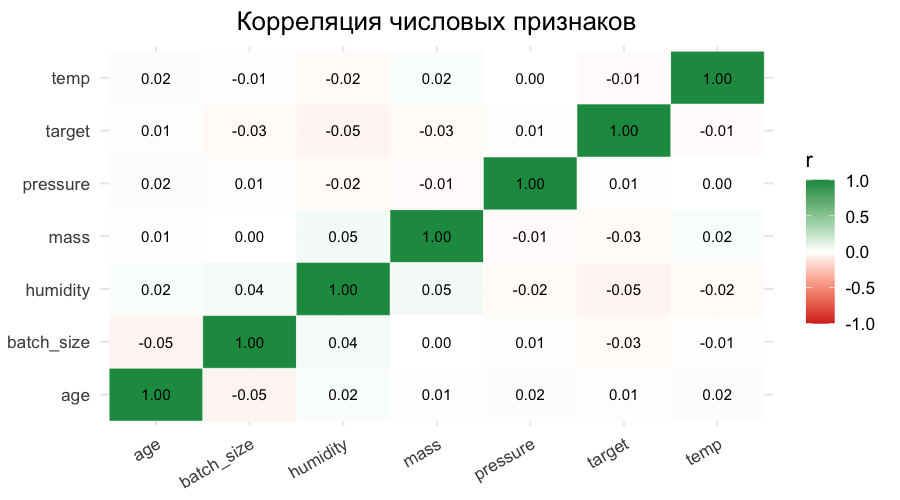

In [23]:
cor_long <- as.data.frame(cor_mat) %>%
  mutate(from = rownames(.)) %>%
  tidyr::pivot_longer(-from, names_to = "to", values_to = "r")
ggplot(cor_long, aes(from, to, fill = r)) +
  geom_tile(color = "white") +
  geom_text(aes(label = sprintf("%.2f", r)), size = 3.2) +
  scale_fill_gradient2(low = "#d73027", mid = "white", high = "#1a9850", midpoint = 0, limits = c(-1, 1)) +
  labs(title = "Корреляция числовых признаков", x = NULL, y = NULL, fill = "r") +
  theme_minimal(base_size = 13) +
  theme(axis.text.x = element_text(angle = 30, hjust = 1), plot.title = element_text(hjust = 0.5))


Более строгая проверка — VIF:


In [24]:
num_model <- lm(num_formula, data = corr_dataset)
vif(num_model)


       age batch_size       mass       temp   pressure   humidity 
  1.003552   1.003927   1.003142   1.001575   1.001125   1.005573 


Если VIF невелик, коэффициенты не искажены взаимосвязанными признаками.

# 6. Равномерность


In [25]:
combined_group <- interaction(
  corr_dataset$factory,
  corr_dataset$year,
  corr_dataset$quarter,
  corr_dataset$batch_no
)
kruskal.test(target ~ combined_group, data = corr_dataset)



	Kruskal-Wallis rank sum test

data:  target by combined_group
Kruskal-Wallis chi-squared = 569.46, df = 524, p-value = 0.08285



Попарные сравнения по площадке (тест Данна с поправкой Бонферрони):


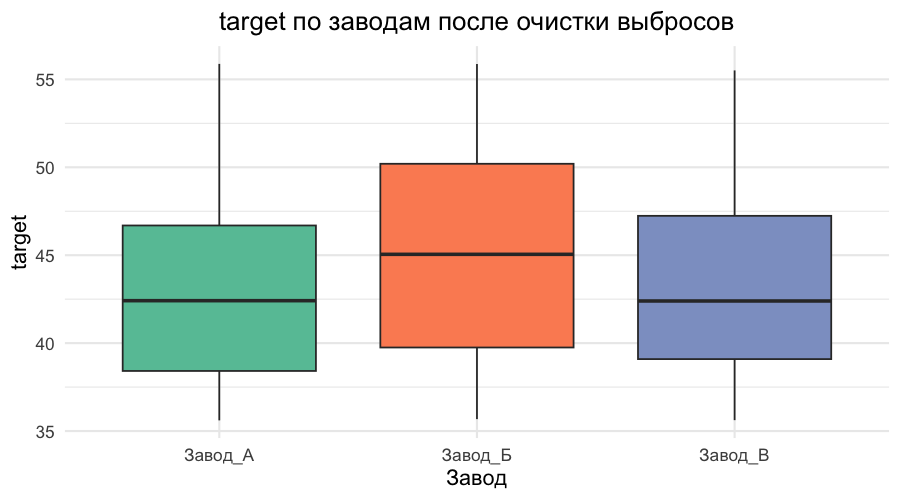

Dunn (1964) Kruskal-Wallis multiple comparison


  p-values adjusted with the Bonferroni method.



         Comparison          Z      P.unadj        P.adj
1 Завод_А - Завод_Б -6.2621230 3.797712e-10 1.139314e-09
2 Завод_А - Завод_В -0.4326951 6.652363e-01 1.000000e+00
3 Завод_Б - Завод_В  3.5016326 4.624168e-04 1.387251e-03


In [26]:
ggplot(corr_dataset, aes(x = factory, y = target, fill = factory)) +
  geom_boxplot(outlier.alpha = 0.3) +
  scale_fill_brewer(palette = "Set2", guide = "none") +
  labs(title = "target по заводам после очистки выбросов", x = "Завод", y = "target") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))
dunnTest(target ~ factory, data = corr_dataset, method = "bonferroni")


# 7. Автокорреляция

Статистика Дарбина–Уотсона по остаткам числовой модели. Значение около 2 говорит об отсутствии автокорреляции.


In [27]:
res <- residuals(num_model)
dw <- sum(diff(res)^2) / sum(res^2)
dw


[1] 1.976583
